# Nhận dạng thực thể có tên (NER) với CRF trên bộ dữ liệu CoNLL-2003

> **Nguồn gốc & ghi công (credits)**
>
> - Notebook này được **chuyển thể, dịch, chú thích và nâng cấp** từ notebook gốc
>   [`docs/CoNLL2002.ipynb`](https://github.com/TeamHG-Memex/sklearn-crfsuite/blob/master/docs/CoNLL2002.ipynb)
>   trong kho mã nguồn **sklearn-crfsuite** của **TeamHG-Memex** (tác giả chính: Mikhail Korobov và cộng sự),
>   phát hành theo giấy phép **MIT**. Hàm trích xuất đặc trưng, cấu hình CRF, phần dò siêu tham số và phần
>   phân tích trọng số đều lấy từ notebook gốc; ý tưởng và mã nguồn gốc thuộc về các tác giả trên.
> - Tài liệu thư viện: <https://sklearn-crfsuite.readthedocs.io/> · thư viện nền:
>   [python-crfsuite](https://github.com/scrapinghub/python-crfsuite) và
>   [CRFsuite](http://www.chokkan.org/software/crfsuite/) (Naoaki Okazaki).
> - Bộ dữ liệu: **CoNLL-2003 Shared Task (tiếng Anh)** — Erik F. Tjong Kim Sang & Fien De Meulder (2003),
>   *"Introduction to the CoNLL-2003 Shared Task: Language-Independent Named Entity Recognition"*, CoNLL-2003.
>   Văn bản lấy từ **Reuters Corpus (RCV1)**; quyền sử dụng văn bản gốc thuộc Reuters/NIST
>   (xem <https://trec.nist.gov/data/reuters/reuters.html>) — **chỉ dùng cho mục đích nghiên cứu, học tập**.
> - Tệp dữ liệu được tải từ bản sao công khai trong kho
>   [synalp/NER](https://github.com/synalp/NER/tree/master/corpus/CoNLL-2003) (giữ nguyên định dạng gốc của CoNLL-2003).
> - Thư viện đánh giá theo thực thể [seqeval](https://github.com/chakki-works/seqeval) (Hiroki Nakayama).
>
> **Những gì đã thay đổi so với bản gốc**
> 1. **Nâng cấp dữ liệu**: từ CoNLL-2002 (tiếng Tây Ban Nha, có sẵn trong NLTK) sang **CoNLL-2003 (tiếng Anh)** —
>    bộ dữ liệu chuẩn được dùng nhiều nhất cho bài toán NER.
> 2. Thêm bước **cài thư viện** và **tự tải dữ liệu**, đọc tệp gốc và **chuyển nhãn IOB1 → IOB2**.
> 3. Thêm phần **phân tích bộ dữ liệu (EDA)**: thống kê, phân bố nhãn, độ dài câu/thực thể, tỉ lệ thực thể "chưa gặp".
> 4. Dò siêu tham số trên **tập phát triển chính thức (dev)** thay vì cross-validation 3 phần (nhanh gấp ~3 lần, đúng chuẩn CoNLL).
> 5. Thêm **đánh giá theo thực thể (entity-level)** bằng `seqeval` — độ đo chính thức của CoNLL — bên cạnh độ đo theo từ của bản gốc.
> 6. Thêm **giải thích chi tiết bằng tiếng Việt** cho mọi bước; biểu đồ dò tham số dùng bảng màu `coolwarm` + thanh màu.

## 0. Tổng quan — notebook này làm gì?

### Bài toán: Nhận dạng thực thể có tên (Named Entity Recognition — NER)
Cho một câu, ta muốn đánh dấu những cụm từ là **tên riêng** và cho biết chúng thuộc loại nào.
CoNLL-2003 có 4 loại thực thể:

| Nhãn | Ý nghĩa | Ví dụ |
|---|---|---|
| `PER` | Người (person) | *Peter Blackburn*, *Clinton* |
| `LOC` | Địa điểm (location) | *Germany*, *Brussels* |
| `ORG` | Tổ chức (organization) | *European Commission*, *EU* |
| `MISC` | Thực thể khác (miscellaneous) | quốc tịch (*German*, *British*), sự kiện, giải đấu… |

### Định dạng nhãn IOB2 (Begin – Inside – Outside)
Một thực thể có thể gồm nhiều từ, nên mỗi **từ** được gán một nhãn:

- `B-XXX`: từ **bắt đầu** (Begin) một thực thể loại XXX;
- `I-XXX`: từ nằm **bên trong** (Inside) thực thể XXX, tiếp nối từ trước đó;
- `O`: từ **không thuộc** (Outside) thực thể nào.

Ví dụ: `EU/B-ORG rejects/O German/B-MISC call/O to/O boycott/O British/B-MISC lamb/O ./O`

Như vậy NER trở thành bài toán **gán nhãn chuỗi (sequence labeling)**: đầu vào là chuỗi từ, đầu ra là chuỗi nhãn cùng độ dài.

### Mô hình: Conditional Random Fields (CRF)
CRF tuyến tính (linear-chain CRF) là mô hình xác suất cho bài toán gán nhãn chuỗi. Khác với việc phân loại
từng từ độc lập, CRF **xét cả chuỗi nhãn cùng lúc**, nhờ hai loại trọng số:

- **Trọng số trạng thái (state features)**: mức độ một đặc trưng của từ (ví dụ "viết hoa chữ cái đầu")
  ủng hộ một nhãn (ví dụ `B-PER`).
- **Trọng số chuyển tiếp (transition features)**: mức độ hợp lý khi nhãn A đứng ngay trước nhãn B
  (ví dụ `B-ORG → I-ORG` rất hợp lý; `O → I-ORG` thì vô lý vì `I-` phải đi sau `B-`/`I-` cùng loại).

Khi dự đoán, CRF chọn **chuỗi nhãn có tổng điểm cao nhất** (thuật toán Viterbi).

### Các bước trong notebook
1. Cài thư viện. 2. Tải và đọc dữ liệu CoNLL-2003. 3. **Phân tích dữ liệu**. 4. Trích xuất đặc trưng.
5. Huấn luyện CRF. 6. Đánh giá (theo từ và theo thực thể). 7. Dò siêu tham số trên tập dev. 8. Xem mô hình đã học được gì.

## 1. Cài đặt và nạp thư viện

| Thư viện | Vai trò |
|---|---|
| `sklearn-crfsuite` | Bọc thư viện CRFsuite thành API giống scikit-learn (`fit`, `predict`…). Tự cài kèm `python-crfsuite`. |
| `scikit-learn` | Dò siêu tham số, tạo hàm chấm điểm. |
| `scipy` | Phân phối xác suất (`scipy.stats.expon`) để lấy mẫu siêu tham số ngẫu nhiên. |
| `seqeval` | Đánh giá **theo thực thể** (entity-level) giống script `conlleval` chính thức của CoNLL. |
| `matplotlib` | Vẽ biểu đồ. |

Lưu ý: cần `sklearn-crfsuite >= 0.5.0`; các bản cũ (0.3.x) không tương thích với scikit-learn đời mới.

`%pip install` là "magic command" của Jupyter: cài gói vào **đúng môi trường Python mà notebook đang dùng**
(đã cài rồi thì bỏ qua). Nếu sau lần cài đầu tiên import bị lỗi, hãy **khởi động lại kernel** (*Kernel → Restart*) rồi chạy lại.

In [1]:
%pip install -q "sklearn-crfsuite>=0.5.0" "scikit-learn>=1.3" scipy seqeval matplotlib


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Nạp thư viện:
- `%matplotlib inline`: hiển thị biểu đồ ngay bên dưới ô code; `plt.style.use('ggplot')`: phong cách vẽ.
- `make_scorer`: biến một hàm tính điểm bất kỳ thành "scorer" mà scikit-learn hiểu được.
- `RandomizedSearchCV`, `PredefinedSplit`: dò siêu tham số ngẫu nhiên trên một cách chia train/dev cố định.
- `sklearn_crfsuite.CRF`: mô hình CRF; `metrics`: độ đo theo từ cho dữ liệu dạng chuỗi.
- `seqeval`: độ đo theo thực thể; `get_entities` tách chuỗi nhãn thành danh sách thực thể `(loại, vị trí đầu, vị trí cuối)`.

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('ggplot')

In [3]:
import os
import urllib.request
from collections import Counter

import scipy.stats
import sklearn
from sklearn.metrics import make_scorer
from sklearn.model_selection import RandomizedSearchCV, PredefinedSplit

import sklearn_crfsuite
from sklearn_crfsuite import metrics

import seqeval.metrics
from seqeval.metrics.sequence_labeling import get_entities

print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.9.1


## 2. Tải và đọc bộ dữ liệu CoNLL-2003

CoNLL-2003 **không** có sẵn trong NLTK như CoNLL-2002. (Cách tải quen thuộc `datasets.load_dataset("conll2003")`
của Hugging Face hiện không dùng được nữa vì đường link dữ liệu mà nó trỏ tới đã ngừng hoạt động.)
Vì vậy ta tải trực tiếp 3 tệp văn bản gốc:

| Tệp | Vai trò | Ghi chú |
|---|---|---|
| `eng.train` | Tập **huấn luyện** (train) | để mô hình học |
| `eng.testa` | Tập **phát triển** (dev / validation) | để chọn siêu tham số, thử đặc trưng |
| `eng.testb` | Tập **kiểm tra cuối** (test) | chỉ dùng để báo cáo kết quả cuối cùng |

Ô dưới tải các tệp về thư mục `data/conll2003/` (cạnh notebook); nếu tệp đã có thì bỏ qua.

In [4]:
DATA_DIR = os.path.join('data', 'conll2003')
BASE_URL = 'https://raw.githubusercontent.com/synalp/NER/master/corpus/CoNLL-2003/'
SPLIT_FILES = {'train': 'eng.train', 'dev': 'eng.testa', 'test': 'eng.testb'}

os.makedirs(DATA_DIR, exist_ok=True)
for split, filename in SPLIT_FILES.items():
    path = os.path.join(DATA_DIR, filename)
    if not os.path.exists(path):
        print('Đang tải', filename, '...')
        urllib.request.urlretrieve(BASE_URL + filename, path)
    print(f'{split:5s} -> {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

train -> data/conll2003/eng.train (3.3 MB)
dev   -> data/conll2003/eng.testa (0.8 MB)
test  -> data/conll2003/eng.testb (0.7 MB)


### Định dạng tệp gốc

Mỗi dòng là **một từ** với 4 cột cách nhau bởi dấu cách: `từ  nhãn_từ_loại(POS)  nhãn_cụm(chunk)  nhãn_thực_thể(NER)`.
- **POS** theo bộ nhãn Penn Treebank: `NNP` = danh từ riêng số ít, `NN` = danh từ chung, `VBZ` = động từ ngôi 3 số ít, `JJ` = tính từ…
- **Chunk**: nhãn cụm cú pháp (`I-NP` = trong cụm danh từ, `I-VP` = trong cụm động từ…). Notebook này không dùng cột này.
- **Dòng trống** ngăn cách các câu; dòng `-DOCSTART-` đánh dấu **bắt đầu một bài báo mới** (không phải câu thật).

Xem 12 dòng đầu của tệp huấn luyện:

In [5]:
with open(os.path.join(DATA_DIR, SPLIT_FILES['train']), encoding='utf-8') as f:
    for _ in range(12):
        print(repr(f.readline()))

'-DOCSTART- -X- O O\n'
'\n'
'EU NNP I-NP I-ORG\n'
'rejects VBZ I-VP O\n'
'German JJ I-NP I-MISC\n'
'call NN I-NP O\n'
'to TO I-VP O\n'
'boycott VB I-VP O\n'
'British JJ I-NP I-MISC\n'
'lamb NN I-NP O\n'
'. . O O\n'
'\n'


### Chuyển nhãn IOB1 → IOB2

Để ý dòng `EU NNP I-NP I-ORG`: từ **đầu tiên** của thực thể lại mang nhãn `I-ORG` chứ không phải `B-ORG`.
Đó là vì tệp gốc dùng lược đồ **IOB1**: nhãn `B-` chỉ xuất hiện khi **hai thực thể cùng loại đứng sát nhau**
(để phân tách chúng); còn lại mọi từ trong thực thể đều là `I-`.

Lược đồ phổ biến hiện nay (và được `seqeval` mặc định) là **IOB2**: **mọi** thực thể đều bắt đầu bằng `B-`.
Quy tắc chuyển: một nhãn `I-X` sẽ thành `B-X` nếu nó đứng **đầu câu**, hoặc nhãn trước nó là `O`, hoặc nhãn trước nó thuộc **loại khác**.

| Từ | IOB1 (gốc) | IOB2 (sau khi chuyển) |
|---|---|---|
| EU | I-ORG | **B-ORG** |
| rejects | O | O |
| German | I-MISC | **B-MISC** |

Hàm `read_conll` đọc tệp thành danh sách **câu**; mỗi câu là danh sách bộ ba `(từ, POS, nhãn IOB2)` —
cùng định dạng với dữ liệu CoNLL-2002 trong NLTK mà notebook gốc dùng, nên các hàm phía sau giữ nguyên được.
Hàm cũng đếm số bài báo (số dòng `-DOCSTART-`).

In [6]:
def iob1_to_iob2(tags):
    # Đổi I-X thành B-X khi nó mở đầu một thực thể (đầu câu, sau O, hoặc sau nhãn khác loại)
    converted = []
    for i, tag in enumerate(tags):
        if tag.startswith('I-') and (i == 0 or tags[i-1] == 'O' or tags[i-1][2:] != tag[2:]):
            converted.append('B-' + tag[2:])
        else:
            converted.append(tag)
    return converted


def read_conll(path):
    # Trả về (danh sách câu, số bài báo); mỗi câu là list các (từ, POS, nhãn IOB2)
    sents, current, n_docs = [], [], 0

    def flush():
        if current:
            tags = iob1_to_iob2([ner for _, _, ner in current])
            sents.append([(w, pos, tag) for (w, pos, _), tag in zip(current, tags)])
            current.clear()

    with open(path, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line.startswith('-DOCSTART-'):
                n_docs += 1
                flush()
            elif not line:
                flush()
            else:
                word, pos, _chunk, ner = line.split()
                current.append((word, pos, ner))
    flush()
    return sents, n_docs


data, n_docs = {}, {}
for split, filename in SPLIT_FILES.items():
    data[split], n_docs[split] = read_conll(os.path.join(DATA_DIR, filename))

train_sents, dev_sents, test_sents = data['train'], data['dev'], data['test']
train_sents[0]

[('EU', 'NNP', 'B-ORG'),
 ('rejects', 'VBZ', 'O'),
 ('German', 'JJ', 'B-MISC'),
 ('call', 'NN', 'O'),
 ('to', 'TO', 'O'),
 ('boycott', 'VB', 'O'),
 ('British', 'JJ', 'B-MISC'),
 ('lamb', 'NN', 'O'),
 ('.', '.', 'O')]

## 3. Phân tích bộ dữ liệu CoNLL-2003 (EDA)

Trước khi huấn luyện, ta tìm hiểu dữ liệu để biết bài toán khó ở đâu.

**Bối cảnh**: dữ liệu tiếng Anh gồm các bản tin của hãng Reuters (năm 1996–1997). Theo bài báo gốc, tập train và dev
lấy từ khoảng **cuối tháng 8/1996**, còn tập test lấy từ **tháng 12/1996** — tức tập test thuộc một giai đoạn thời sự khác,
chứa nhiều tên riêng mới. Điều này sẽ thể hiện rõ ở mục 3.5.

### 3.1. Kích thước các tập

In [7]:
print(f"{'Tập':6s} {'Bài báo':>8s} {'Câu':>8s} {'Từ':>9s} {'Thực thể':>9s}")
for split, sents in data.items():
    n_tokens = sum(len(s) for s in sents)
    n_entities = sum(len(get_entities([t for _, _, t in s])) for s in sents)
    print(f'{split:6s} {n_docs[split]:8d} {len(sents):8d} {n_tokens:9d} {n_entities:9d}')

Tập     Bài báo      Câu        Từ  Thực thể
train       946    14041    203621     23499
dev         216     3250     51362      5942
test        231     3453     46435      5648


Số liệu trên khớp với bảng thống kê trong bài báo CoNLL-2003 (ví dụ tập train: 946 bài báo, 14.041 câu, 203.621 từ),
chứng tỏ dữ liệu được tải và đọc đúng.

### 3.2. Số thực thể theo loại

`get_entities` gom các nhãn `B-X I-X I-X…` liên tiếp thành **một thực thể**. Ta đếm số thực thể mỗi loại ở từng tập.

Loại     train     dev    test
PER       6600    1842    1617
LOC       7140    1837    1668
ORG       6321    1341    1661
MISC      3438     922     702


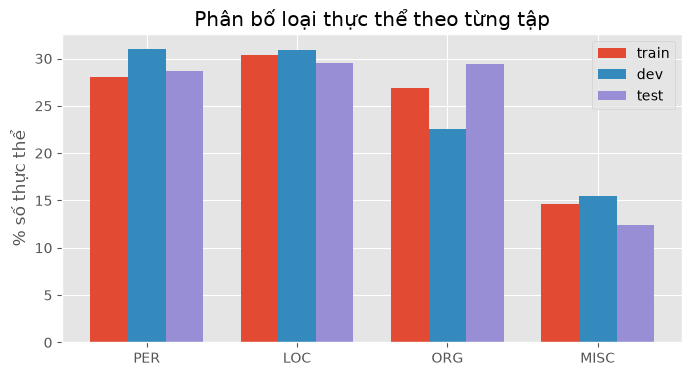

In [8]:
entity_types = ['PER', 'LOC', 'ORG', 'MISC']
entity_counts = {
    split: Counter(ent_type for s in sents for ent_type, _, _ in get_entities([t for _, _, t in s]))
    for split, sents in data.items()
}

print(f"{'Loại':6s}" + ''.join(f'{split:>8s}' for split in data))
for ent_type in entity_types:
    print(f'{ent_type:6s}' + ''.join(f'{entity_counts[split][ent_type]:8d}' for split in data))

# Biểu đồ cột: tỉ lệ (%) từng loại trong mỗi tập để so sánh phân bố giữa các tập
fig, ax = plt.subplots(figsize=(8, 4))
width = 0.25
for k, split in enumerate(data):
    total = sum(entity_counts[split].values())
    ax.bar([i + k * width for i in range(len(entity_types))],
           [100 * entity_counts[split][t] / total for t in entity_types],
           width, label=split)
ax.set_xticks([i + width for i in range(len(entity_types))])
ax.set_xticklabels(entity_types)
ax.set_ylabel('% số thực thể')
ax.set_title('Phân bố loại thực thể theo từng tập')
ax.legend()
plt.show()

Nhận xét: bốn loại khá cân bằng; `MISC` ít nhất. Phân bố giữa train/dev/test tương đối giống nhau
(tập test có tỉ lệ `ORG` cao hơn một chút).

### 3.3. Phân bố nhãn theo từ — nhãn `O` áp đảo

Đếm nhãn ở mức **từ** trong tập train. Phần lớn các từ là `O`. Vì vậy khi đánh giá, ta **loại `O`** ra —
nếu không, mô hình chỉ cần đoán `O` cho mọi từ cũng đã đạt "độ chính xác" rất cao, nhưng vô dụng.

In [9]:
label_counts = Counter(tag for s in train_sents for _, _, tag in s)
total = sum(label_counts.values())
for label, count in label_counts.most_common():
    print(f'{label:7s} {count:7d}  ({100 * count / total:5.2f}%)')

O        169578  (83.28%)
B-LOC      7140  ( 3.51%)
B-PER      6600  ( 3.24%)
B-ORG      6321  ( 3.10%)
I-PER      4528  ( 2.22%)
I-ORG      3704  ( 1.82%)
B-MISC     3438  ( 1.69%)
I-LOC      1157  ( 0.57%)
I-MISC     1155  ( 0.57%)


### 3.4. Độ dài câu và độ dài thực thể

- **Độ dài câu**: CoNLL-2003 có rất nhiều câu cực ngắn (tiêu đề, dòng tỉ số thể thao, ngày tháng như `BRUSSELS 1996-08-22`).
- **Độ dài thực thể**: đa số thực thể chỉ gồm 1–2 từ.

Câu: trung bình 14.5 từ, dài nhất 113 từ; 13.5% số câu có <= 3 từ
Độ dài thực thể (số từ -> số thực thể): [(1, 14831), (2, 7384), (3, 904), (4, 250), (5, 82), (6, 25), (7, 18), (8, 2), (10, 3)]


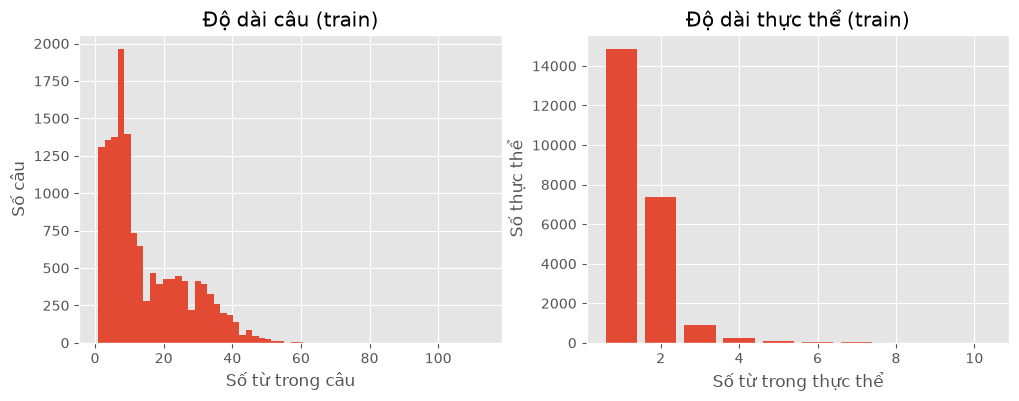

In [10]:
sent_lengths = [len(s) for s in train_sents]
entity_lengths = [end - start + 1
                  for s in train_sents
                  for _, start, end in get_entities([t for _, _, t in s])]

print('Câu: trung bình %.1f từ, dài nhất %d từ; %.1f%% số câu có <= 3 từ' % (
    sum(sent_lengths) / len(sent_lengths), max(sent_lengths),
    100 * sum(l <= 3 for l in sent_lengths) / len(sent_lengths)))
print('Độ dài thực thể (số từ -> số thực thể):', sorted(Counter(entity_lengths).items()))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.hist(sent_lengths, bins=60)
ax1.set_xlabel('Số từ trong câu')
ax1.set_ylabel('Số câu')
ax1.set_title('Độ dài câu (train)')
length_counts = Counter(entity_lengths)
ax2.bar(list(length_counts), list(length_counts.values()))
ax2.set_xlabel('Số từ trong thực thể')
ax2.set_ylabel('Số thực thể')
ax2.set_title('Độ dài thực thể (train)')
plt.show()

### 3.5. Thực thể phổ biến và thực thể "chưa gặp" (unseen)

Liệt kê các thực thể xuất hiện nhiều nhất trong tập train theo từng loại, rồi tính: trong tập dev/test,
bao nhiêu % thực thể **chưa từng xuất hiện** (cùng chuỗi chữ, cùng loại) trong tập train.

Đây là thước đo quan trọng: mô hình "học thuộc" tên riêng sẽ làm tốt với thực thể đã gặp,
nhưng muốn đoán đúng thực thể **chưa gặp** thì phải dựa vào **ngữ cảnh** và **hình dạng từ** (viết hoa, hậu tố…).

In [11]:
def entity_mentions(sents):
    # Danh sách (chuỗi thực thể, loại) có trong tập dữ liệu
    mentions = []
    for s in sents:
        words = [w for w, _, _ in s]
        for ent_type, start, end in get_entities([t for _, _, t in s]):
            mentions.append((' '.join(words[start:end + 1]), ent_type))
    return mentions

train_mentions = entity_mentions(train_sents)
for ent_type in entity_types:
    top = Counter(m for m, t in train_mentions if t == ent_type).most_common(8)
    print(f'{ent_type:5s}:', ', '.join(f'{m} ({c})' for m, c in top))

seen = set(train_mentions)
print()
for split in ['dev', 'test']:
    mentions = entity_mentions(data[split])
    unseen = sum(m not in seen for m in mentions)
    print(f'{split}: {100 * unseen / len(mentions):.1f}% thực thể chưa từng xuất hiện trong train')

PER  : Clinton (70), Dole (36), Arafat (35), Yeltsin (32), Lebed (30), Dutroux (30), Wasim Akram (29), Waqar Younis (25)
LOC  : U.S. (303), Germany (141), Britain (133), Australia (130), England (123), France (122), Spain (110), Italy (98)
ORG  : Reuters (73), U.N. (35), NEW YORK (30), CHICAGO (30), PUK (25), OSCE (25), EU (23), NATO (22)
MISC : Russian (92), German (80), British (73), French (59), Dutch (50), GMT (49), Israeli (48), English (38)

dev: 32.6% thực thể chưa từng xuất hiện trong train
test: 47.5% thực thể chưa từng xuất hiện trong train


Nhận xét: tỉ lệ thực thể chưa gặp trong **test cao hơn hẳn dev** — hệ quả của việc test lấy từ giai đoạn thời sự khác.
Vì vậy điểm trên tập test thường **thấp hơn** trên tập dev; đây là đặc điểm nổi tiếng của CoNLL-2003.

### 3.6. Từ loại (POS) của các từ thuộc thực thể

Phần lớn các từ thuộc thực thể có POS là `NNP` (danh từ riêng) — gợi ý rằng POS là một đặc trưng rất có ích.
Tuy nhiên `MISC` hay có `JJ` (tính từ, ví dụ *German*, *British*) và `NNPS`.

In [12]:
pos_by_type = {t: Counter() for t in entity_types}
for s in train_sents:
    for _, pos, tag in s:
        if tag != 'O':
            pos_by_type[tag[2:]][pos] += 1

for ent_type in entity_types:
    total = sum(pos_by_type[ent_type].values())
    top = pos_by_type[ent_type].most_common(4)
    print(f'{ent_type:5s}:', ', '.join(f'{pos} {100 * c / total:.0f}%' for pos, c in top))

PER  : NNP 94%, NN 2%, JJ 1%, NNPS 1%
LOC  : NNP 92%, NN 2%, JJ 1%, NNPS 1%
ORG  : NNP 83%, NN 4%, NNPS 3%, JJ 2%
MISC : NNP 51%, JJ 34%, NNPS 4%, NN 3%


### Tóm tắt phân tích

| Đặc điểm | Hệ quả cho mô hình |
|---|---|
| Nhãn `O` chiếm ~83% số từ | Đánh giá phải bỏ `O`; nên dùng F1 theo thực thể. |
| Nhiều câu rất ngắn (tiêu đề, tỉ số, ngày tháng) | Ngữ cảnh ít → đặc trưng của chính từ (viết hoa, hậu tố, POS) rất quan trọng. |
| Thực thể thường dài 1–2 từ | Cửa sổ ngữ cảnh ±1 từ là điểm khởi đầu hợp lý. |
| Test có nhiều thực thể chưa gặp hơn dev | Điểm test thấp hơn dev; cần đặc trưng tổng quát, không chỉ "học thuộc" tên. |
| `NNP` chiếm phần lớn từ thuộc thực thể | POS là đặc trưng mạnh; `MISC` khó hơn vì đa dạng (tính từ quốc tịch, sự kiện…). |

## 4. Trích xuất đặc trưng (Features)

CRF không "đọc" được chữ trực tiếp; ta mô tả mỗi từ bằng một **dict** `{tên đặc trưng: giá trị}`.
Giá trị kiểu chuỗi (ví dụ `'word.lower()': 'germany'`) được hiểu là một đặc trưng nhị phân "từ viết thường là germany";
giá trị số/bool được dùng làm trọng số. Bộ đặc trưng giữ **nguyên như notebook gốc**:

**Đặc trưng của chính từ đang xét:**

| Đặc trưng | Ý nghĩa | Vì sao hữu ích? |
|---|---|---|
| `bias` | Luôn bằng 1.0 | Như hệ số chặn, cho phép mô hình học "độ phổ biến" của từng nhãn. |
| `word.lower()` | Từ viết thường | Nhớ các từ cụ thể (ví dụ "germany" thường là `LOC`). |
| `word[-3:]`, `word[-2:]` | 3 và 2 ký tự cuối (hậu tố) | Hậu tố gợi ý loại từ (ví dụ "-ian" hay gặp ở tính từ quốc tịch → `MISC`). |
| `word.isupper()` | Viết HOA toàn bộ? | Tên viết tắt tổ chức (EU, UN, NATO) và tiêu đề tin. |
| `word.istitle()` | Viết hoa chữ cái đầu? | Tên riêng tiếng Anh luôn viết hoa chữ đầu. |
| `word.isdigit()` | Toàn chữ số? | Số hầu như không bao giờ là thực thể. |
| `postag` | Nhãn từ loại | `NNP` (danh từ riêng) rất hay là thực thể (xem mục 3.6). |
| `postag[:2]` | 2 ký tự đầu của POS | Gộp nhãn chi tiết thành nhóm thô (`NNP`, `NNPS` → `NN`; `VBZ`, `VBD` → `VB`). |

**Đặc trưng ngữ cảnh** (từ liền trước `-1:` và liền sau `+1:`): viết thường, viết hoa, từ loại của từ bên cạnh.
Ví dụ từ trước là "President" thì từ hiện tại rất có thể là tên người.

- Từ **đầu câu** không có từ trước → thêm đặc trưng `BOS` (Beginning Of Sentence).
- Từ **cuối câu** không có từ sau → thêm đặc trưng `EOS` (End Of Sentence).

Ba hàm phụ trợ: `sent2features` (câu → danh sách dict, đầu vào **X**), `sent2labels` (câu → danh sách nhãn, đầu ra **y**),
`sent2tokens` (câu → danh sách từ, để hiển thị).

In [13]:
def word2features(sent, i):
    # Đặc trưng của từ thứ i trong câu `sent`; mỗi phần tử của câu là (từ, POS, nhãn)
    word = sent[i][0]
    postag = sent[i][1]

    features = {
        'bias': 1.0,
        'word.lower()': word.lower(),
        'word[-3:]': word[-3:],
        'word[-2:]': word[-2:],
        'word.isupper()': word.isupper(),
        'word.istitle()': word.istitle(),
        'word.isdigit()': word.isdigit(),
        'postag': postag,
        'postag[:2]': postag[:2],
    }
    # Ngữ cảnh: từ liền trước (nếu có), ngược lại đánh dấu đầu câu
    if i > 0:
        word1 = sent[i-1][0]
        postag1 = sent[i-1][1]
        features.update({
            '-1:word.lower()': word1.lower(),
            '-1:word.istitle()': word1.istitle(),
            '-1:word.isupper()': word1.isupper(),
            '-1:postag': postag1,
            '-1:postag[:2]': postag1[:2],
        })
    else:
        features['BOS'] = True

    # Ngữ cảnh: từ liền sau (nếu có), ngược lại đánh dấu cuối câu
    if i < len(sent)-1:
        word1 = sent[i+1][0]
        postag1 = sent[i+1][1]
        features.update({
            '+1:word.lower()': word1.lower(),
            '+1:word.istitle()': word1.istitle(),
            '+1:word.isupper()': word1.isupper(),
            '+1:postag': postag1,
            '+1:postag[:2]': postag1[:2],
        })
    else:
        features['EOS'] = True

    return features


def sent2features(sent):
    return [word2features(sent, i) for i in range(len(sent))]

def sent2labels(sent):
    return [label for token, postag, label in sent]

def sent2tokens(sent):
    return [token for token, postag, label in sent]

Xem đặc trưng của **từ đầu tiên** ("EU") trong câu đầu tiên: có `BOS: True`, không có đặc trưng `-1:...`.

In [14]:
sent2features(train_sents[0])[0]

{'bias': 1.0,
 'word.lower()': 'eu',
 'word[-3:]': 'EU',
 'word[-2:]': 'EU',
 'word.isupper()': True,
 'word.istitle()': False,
 'word.isdigit()': False,
 'postag': 'NNP',
 'postag[:2]': 'NN',
 'BOS': True,
 '+1:word.lower()': 'rejects',
 '+1:word.istitle()': False,
 '+1:word.isupper()': False,
 '+1:postag': 'VBZ',
 '+1:postag[:2]': 'VB'}

Áp dụng cho cả 3 tập. Dữ liệu có dạng **"danh sách lồng danh sách"** (theo câu) chứ không phải bảng phẳng —
vì CRF cần biết ranh giới câu để học quan hệ giữa các nhãn liền kề.

In [15]:
%%time
X_train = [sent2features(s) for s in train_sents]
y_train = [sent2labels(s) for s in train_sents]

X_dev = [sent2features(s) for s in dev_sents]
y_dev = [sent2labels(s) for s in dev_sents]

X_test = [sent2features(s) for s in test_sents]
y_test = [sent2labels(s) for s in test_sents]

CPU times: user 194 ms, sys: 17 ms, total: 211 ms
Wall time: 211 ms


## 5. Huấn luyện mô hình CRF

Các tham số của `sklearn_crfsuite.CRF` (xem đầy đủ bằng `help(sklearn_crfsuite.CRF)`):

| Tham số | Giá trị | Ý nghĩa |
|---|---|---|
| `algorithm` | `'lbfgs'` | Thuật toán tối ưu L-BFGS (mặc định) — hội tụ nhanh và ổn định. |
| `c1` | `0.1` | Hệ số **điều chuẩn L1**: đẩy nhiều trọng số về đúng 0 → mô hình **thưa**, gọn, tự loại đặc trưng vô ích. |
| `c2` | `0.1` | Hệ số **điều chuẩn L2**: phạt trọng số lớn → giảm **quá khớp (overfitting)**. |
| `max_iterations` | `100` | Số vòng lặp tối ưu tối đa. |
| `all_possible_transitions` | `True` | Tạo trọng số chuyển tiếp cho **mọi** cặp nhãn, kể cả cặp chưa từng xuất hiện — để mô hình học được trọng số **âm** cho chuyển tiếp vô lý (ví dụ `O → I-PER`). |

Kết hợp L1 + L2 gọi là điều chuẩn **Elastic Net**. Mô hình này (gọi là **baseline**) chỉ học trên tập **train**;
thường mất khoảng 1 phút tuỳ máy.

In [16]:
%%time
crf = sklearn_crfsuite.CRF(
    algorithm='lbfgs',
    c1=0.1,
    c2=0.1,
    max_iterations=100,
    all_possible_transitions=True
)
crf.fit(X_train, y_train)

CPU times: user 8.1 s, sys: 73.3 ms, total: 8.17 s
Wall time: 8.22 s


,algorithm,'lbfgs'
,all_possible_transitions,True
,c1,0.1
,c2,0.1
,max_iterations,100
,min_freq,None
,all_possible_states,None
,num_memories,None
,epsilon,None
,period,None
,delta,None


## 6. Đánh giá mô hình

### Các độ đo
- **Precision (độ chính xác)** = trong số những gì mô hình gán là X, bao nhiêu % đúng.
- **Recall (độ phủ)** = trong số những X thật sự, mô hình tìm ra bao nhiêu %.
- **F1** = trung bình điều hoà: $F1 = \dfrac{2 \cdot P \cdot R}{P + R}$.

Có **hai cách** tính:

1. **Theo từ (token-level)** — cách của notebook gốc: so sánh nhãn của từng từ, **bỏ nhãn `O`**.
2. **Theo thực thể (entity-level)** — cách **chính thức của CoNLL** (script `conlleval`), dùng `seqeval`:
   một thực thể chỉ được tính là đúng khi mô hình đoán **đúng cả ranh giới (từ đầu → từ cuối) lẫn loại**.
   Ví dụ thực thể thật "European Commission" (ORG) mà mô hình chỉ đoán "Commission" là ORG → tính là **sai hoàn toàn**.
   Cách này khắt khe hơn và là con số dùng để so sánh với các bài báo.

`crf.classes_` là danh sách nhãn mô hình đã thấy. Ta bỏ `O` ra để dùng cho độ đo theo từ.

In [17]:
labels = list(crf.classes_)
labels.remove('O')
labels

['B-ORG', 'B-MISC', 'B-PER', 'I-PER', 'B-LOC', 'I-ORG', 'I-MISC', 'I-LOC']

Dự đoán trên tập **test** và tính hai loại F1:
- `metrics.flat_f1_score(..., average='weighted')`: F1 theo từ, trung bình có trọng số theo số lượng mỗi nhãn
  (`flat_` = "làm phẳng" danh sách các câu thành một danh sách nhãn dài);
- `seqeval.metrics.f1_score`: F1 theo thực thể (micro-average trên tất cả thực thể).

In [18]:
y_pred = crf.predict(X_test)
print('F1 theo từ (bỏ O)  :', round(metrics.flat_f1_score(y_test, y_pred, average='weighted', labels=labels), 4))
print('F1 theo thực thể   :', round(seqeval.metrics.f1_score(y_test, y_pred), 4))

F1 theo từ (bỏ O)  : 0.8014
F1 theo thực thể   : 0.7902


### Báo cáo chi tiết

**Theo từ**: sắp xếp nhãn để `B-` và `I-` cùng loại nằm cạnh nhau. Cột `support` = số từ thật sự mang nhãn đó.

In [19]:
# Gom kết quả B- và I- của cùng một loại thực thể nằm cạnh nhau
sorted_labels = sorted(
    labels,
    key=lambda name: (name[1:], name[0])
)
print(metrics.flat_classification_report(
    y_test, y_pred, labels=sorted_labels, digits=3
))

              precision    recall  f1-score   support

       B-LOC      0.856     0.814     0.834      1668
       I-LOC      0.745     0.626     0.681       257
      B-MISC      0.819     0.754     0.785       702
      I-MISC      0.688     0.653     0.670       216
       B-ORG      0.775     0.727     0.750      1661
       I-ORG      0.679     0.734     0.705       835
       B-PER      0.822     0.860     0.841      1617
       I-PER      0.861     0.951     0.904      1156

   micro avg      0.804     0.801     0.803      8112
   macro avg      0.781     0.765     0.771      8112
weighted avg      0.804     0.801     0.801      8112



**Theo thực thể**: mỗi dòng là một loại thực thể; `support` = số thực thể thật.
`micro avg` là con số F1 chính thức hay được báo cáo cho CoNLL-2003.

In [20]:
print(seqeval.metrics.classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

         LOC      0.847     0.806     0.826      1668
        MISC      0.800     0.736     0.767       702
         ORG      0.742     0.695     0.718      1661
         PER      0.816     0.854     0.835      1617

   micro avg      0.802     0.779     0.790      5648
   macro avg      0.801     0.773     0.786      5648
weighted avg      0.802     0.779     0.789      5648



### Xem dự đoán trên một câu cụ thể

So sánh nhãn thật và nhãn dự đoán cho từng từ. Dòng có dấu `✗` là chỗ mô hình đoán sai. Đổi `idx` để xem câu khác.

In [21]:
idx = 2  # chỉ số câu trong tập test, thử đổi sang số khác
print(f"{'Từ':20s} {'Nhãn thật':10s} {'Dự đoán':10s}")
for token, true_label, pred_label in zip(sent2tokens(test_sents[idx]), y_test[idx], y_pred[idx]):
    mark = '' if true_label == pred_label else '  ✗'
    print(f'{token:20s} {true_label:10s} {pred_label:10s}{mark}')

Từ                   Nhãn thật  Dự đoán   
AL-AIN               B-LOC      B-LOC     
,                    O          O         
United               B-LOC      B-ORG       ✗
Arab                 I-LOC      I-ORG       ✗
Emirates             I-LOC      I-ORG       ✗
1996-12-06           O          O         


## 7. Dò tìm siêu tham số (Hyperparameter Optimization)

Ở bước 5, ta chọn `c1 = c2 = 0.1` một cách cảm tính. Giờ ta **thử nhiều cặp `(c1, c2)`** và chọn cặp tốt nhất.

### Randomized Search trên tập dev
- **Randomized Search**: thay vì thử mọi tổ hợp trên lưới (grid search — rất tốn kém), ta **lấy mẫu ngẫu nhiên**
  `N_ITER` cặp `(c1, c2)` từ các phân phối cho trước.
- **Đánh giá trên tập dev**: notebook gốc dùng cross-validation 3 phần (mỗi cặp tham số phải huấn luyện 3 lần).
  CoNLL-2003 đã có sẵn **tập phát triển chính thức** (`eng.testa`), nên mỗi cặp chỉ cần **huấn luyện 1 lần trên train, chấm điểm trên dev**
  → nhanh gấp ~3 lần và đúng quy trình chuẩn. Quan trọng nhất: **không dùng tập test** khi chọn tham số (tránh "nhìn trộm" đáp án).
- Để `RandomizedSearchCV` hiểu cách chia này, ta ghép train + dev và dùng `PredefinedSplit`:
  `test_fold = -1` nghĩa là "luôn dùng để huấn luyện", `test_fold = 0` nghĩa là "dùng để chấm điểm".

### Không gian tìm kiếm & hàm chấm điểm
- `c1 ~ Exponential(scale=0.5)`, `c2 ~ Exponential(scale=0.05)`: phân phối mũ cho ra phần lớn giá trị nhỏ, thỉnh thoảng có giá trị lớn —
  phù hợp với hệ số điều chuẩn. `scale` là giá trị trung bình của phân phối.
- Hàm chấm điểm: **F1 theo thực thể** (`seqeval`) — chính là độ đo ta quan tâm cuối cùng.
- `random_state=42`: cố định việc lấy mẫu ngẫu nhiên để chạy lại cho cùng kết quả.
- `n_jobs=-1`: dùng **tất cả** nhân CPU chạy song song; `verbose=1`: in tiến độ.
- `refit=False`: không tự huấn luyện lại; ta sẽ tự huấn luyện mô hình cuối **chỉ trên train** với tham số tốt nhất,
  để so sánh công bằng với baseline ở bước 5.

> ⚠️ **Bước này tốn CPU và RAM**: cần huấn luyện `N_ITER` mô hình (mặc định 50), có thể mất từ vài phút đến vài chục phút.
> Nếu máy yếu, hãy **giảm `N_ITER`** (ví dụ 10).

In [22]:
%%time
N_ITER = 50  # số cặp (c1, c2) được thử; giảm xuống (ví dụ 10) nếu máy chạy chậm

# Ghép train + dev; PredefinedSplit: -1 = luôn để huấn luyện, 0 = dùng để chấm điểm
X_train_dev = X_train + X_dev
y_train_dev = y_train + y_dev
dev_split = PredefinedSplit([-1] * len(X_train) + [0] * len(X_dev))

# Các tham số cố định
crf = sklearn_crfsuite.CRF(
    algorithm='lbfgs',
    max_iterations=100,
    all_possible_transitions=True
)
# Các tham số cần dò: lấy mẫu từ phân phối mũ
params_space = {
    'c1': scipy.stats.expon(scale=0.5),
    'c2': scipy.stats.expon(scale=0.05),
}

# Chấm điểm bằng F1 theo thực thể
f1_scorer = make_scorer(seqeval.metrics.f1_score)

rs = RandomizedSearchCV(crf, params_space,
                        cv=dev_split,
                        verbose=1,
                        n_jobs=-1,
                        n_iter=N_ITER,
                        scoring=f1_scorer,
                        refit=False,
                        random_state=42)
rs.fit(X_train_dev, y_train_dev)

Fitting 1 folds for each of 50 candidates, totalling 50 fits
CPU times: user 18.2 s, sys: 1.08 s, total: 19.3 s
Wall time: 1min 30s


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",CRF(algorithm...terations=100)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'c1': <scipy.stats....t 0x1316143d0>, 'c2': <scipy.stats....t 0x11a10dbd0>}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",make_scorer(f...hod='predict')
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",False
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User G

### Kết quả tốt nhất

- `best_params_`: cặp `(c1, c2)` cho F1 trên dev cao nhất; `best_score_`: điểm F1 (theo thực thể) trên dev của cặp đó.

In [23]:
print('best params:', rs.best_params_)
print('best dev F1:', round(rs.best_score_, 4))

best params: {'c1': np.float64(0.0027687101879677375), 'c2': np.float64(0.08449483887430631)}
best dev F1: 0.877


### Trực quan hoá không gian tham số

Mỗi chấm là một cặp `(c1, c2)` đã thử; **màu** là F1 trên dev: **đỏ = tốt hơn, xanh = kém hơn**.
Hai trục dùng thang **logarit** vì giá trị trải rộng nhiều bậc độ lớn. Biểu đồ cho thấy vùng tham số tốt để thu hẹp tìm kiếm lần sau.

Dark blue => 0.8316, dark red => 0.877


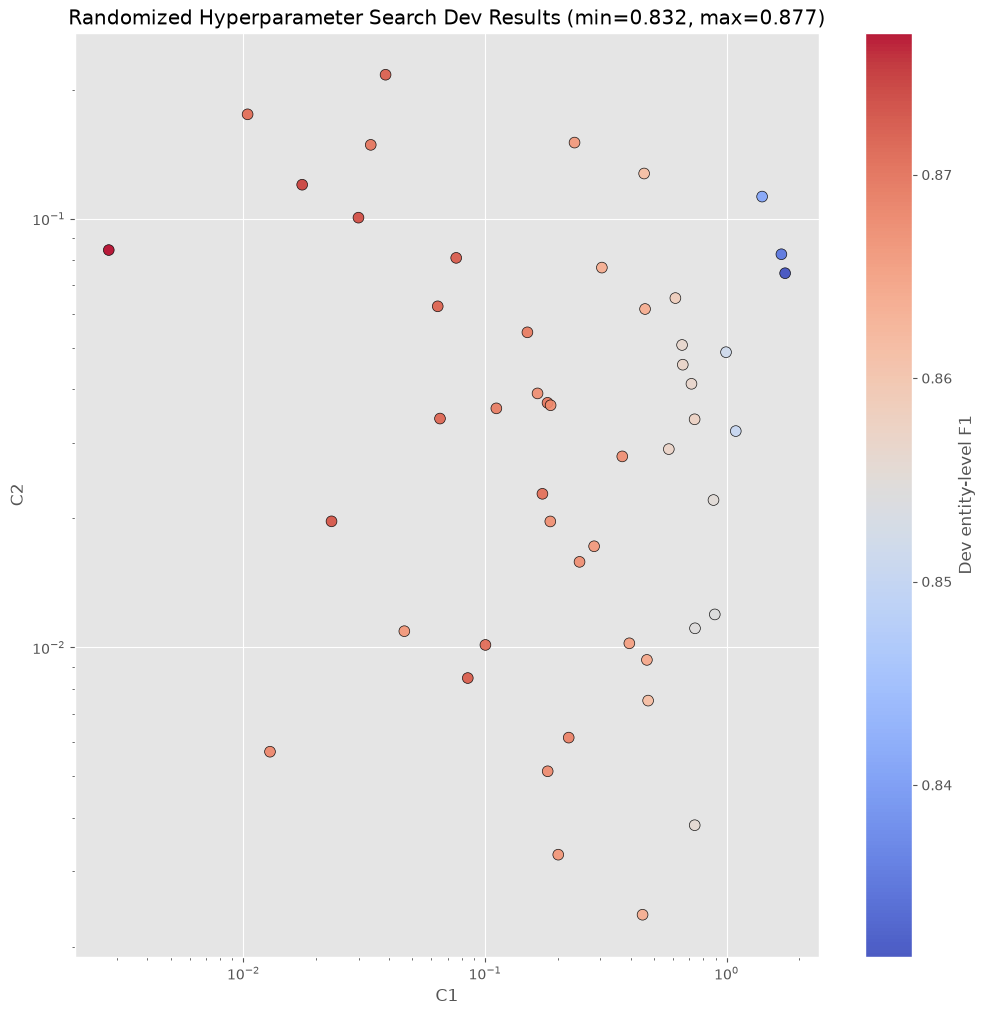

In [24]:
_x = [s['c1'] for s in rs.cv_results_['params']]
_y = [s['c2'] for s in rs.cv_results_['params']]
_c = [s for s in rs.cv_results_['mean_test_score']]

fig = plt.figure()
fig.set_size_inches(12, 12)
ax = plt.gca()
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_xlabel('C1')
ax.set_ylabel('C2')
ax.set_title("Randomized Hyperparameter Search Dev Results (min={:0.3}, max={:0.3})".format(
    min(_c), max(_c)
))

# cmap='coolwarm': xanh = điểm thấp, đỏ = điểm cao
points = ax.scatter(_x, _y, c=_c, s=60, alpha=0.9, edgecolors=[0,0,0], cmap='coolwarm')
fig.colorbar(points, ax=ax, label='Dev entity-level F1')

print("Dark blue => {:0.4}, dark red => {:0.4}".format(min(_c), max(_c)))

### Huấn luyện mô hình cuối và kiểm tra trên tập test

Huấn luyện lại CRF trên **train** với cặp `(c1, c2)` tốt nhất, rồi đánh giá **một lần** trên tập test.
`size_` là kích thước mô hình (byte) — `c1` càng lớn thì mô hình càng thưa, càng nhỏ.

Thông thường điểm sẽ **nhỉnh hơn** baseline. Cũng để ý điểm test thấp hơn điểm dev — đúng như phân tích ở mục 3.5.

In [25]:
%%time
crf = sklearn_crfsuite.CRF(
    algorithm='lbfgs',
    max_iterations=100,
    all_possible_transitions=True,
    **rs.best_params_
)
crf.fit(X_train, y_train)
print('model size: {:0.2f}M'.format(crf.size_ / 1000000))

y_pred = crf.predict(X_test)
print('F1 theo từ (bỏ O)  :', round(metrics.flat_f1_score(y_test, y_pred, average='weighted', labels=labels), 4))
print('F1 theo thực thể   :', round(seqeval.metrics.f1_score(y_test, y_pred), 4))
print()
print(seqeval.metrics.classification_report(y_test, y_pred, digits=3))

model size: 3.03M
F1 theo từ (bỏ O)  : 0.8071
F1 theo thực thể   : 0.7946

              precision    recall  f1-score   support

         LOC      0.855     0.821     0.838      1668
        MISC      0.791     0.745     0.767       702
         ORG      0.736     0.699     0.717      1661
         PER      0.833     0.847     0.840      1617

   micro avg      0.806     0.783     0.795      5648
   macro avg      0.804     0.778     0.790      5648
weighted avg      0.806     0.783     0.794      5648

CPU times: user 8.9 s, sys: 107 ms, total: 9 s
Wall time: 9.36 s


## 8. Mô hình đã học được gì?

Ưu điểm lớn của CRF so với mạng nơ-ron là **dễ diễn giải**: ta có thể đọc trực tiếp các trọng số.

### Trọng số chuyển tiếp (transition features)
`crf.transition_features_` là dict `{(nhãn_trước, nhãn_sau): trọng_số}`.
Trọng số **dương lớn** → chuyển tiếp hay xảy ra; **âm lớn** → gần như không thể xảy ra.
`Counter(...).most_common(20)` lấy 20 cặp lớn nhất; `most_common()[-20:]` lấy 20 cặp nhỏ nhất.

In [26]:
def print_transitions(trans_features):
    for (label_from, label_to), weight in trans_features:
        print("%-6s -> %-7s %0.6f" % (label_from, label_to, weight))

print("Top likely transitions:")
print_transitions(Counter(crf.transition_features_).most_common(20))

print("\nTop unlikely transitions:")
print_transitions(Counter(crf.transition_features_).most_common()[-20:])

Top likely transitions:
B-PER  -> I-PER   5.378681
B-LOC  -> I-LOC   5.296110
B-MISC -> I-MISC  4.957962
I-ORG  -> I-ORG   4.851531
I-MISC -> I-MISC  4.850054
I-LOC  -> I-LOC   4.649549
B-ORG  -> I-ORG   4.369786
I-PER  -> I-PER   3.206599
O      -> O       3.014928
O      -> B-PER   1.861120
O      -> B-ORG   1.356211
O      -> B-LOC   1.070021
O      -> B-MISC  0.854225
B-MISC -> O       0.370451
B-LOC  -> O       0.286632
B-PER  -> O       -0.000078
I-ORG  -> O       -0.156918
I-PER  -> O       -0.275143
I-LOC  -> O       -0.341952
B-MISC -> B-ORG   -0.397116

Top unlikely transitions:
B-PER  -> B-MISC  -2.920372
I-ORG  -> B-PER   -2.928895
B-MISC -> I-PER   -3.016971
I-ORG  -> I-PER   -3.060910
B-PER  -> B-ORG   -3.165169
B-LOC  -> I-MISC  -3.253690
B-LOC  -> B-PER   -3.270781
B-ORG  -> I-MISC  -3.271482
B-ORG  -> B-PER   -3.468828
I-PER  -> B-PER   -3.504794
B-LOC  -> I-PER   -3.553395
B-ORG  -> I-PER   -3.730914
B-ORG  -> B-LOC   -3.763528
O      -> I-PER   -4.283584
B-PER  -> B-

Ví dụ: `B-ORG → I-ORG`, `B-PER → I-PER`… có trọng số dương lớn (từ đầu tên thường được nối tiếp bởi phần còn lại của tên),
trong khi các chuyển tiếp như `O → I-PER` hay `B-LOC → I-ORG` bị phạt nặng — mô hình đã tự học
**quy tắc của định dạng IOB2** mà không ai lập trình sẵn.

### Trọng số trạng thái (state features)
`crf.state_features_` là dict `{(tên_đặc_trưng, nhãn): trọng_số}`. Mỗi dòng in ra có dạng `trọng_số  nhãn  đặc_trưng`,
ví dụ `5.70 B-ORG -1:word.lower():v` nghĩa là "nếu từ liền trước là *v* thì ủng hộ mạnh nhãn `B-ORG` cho từ hiện tại".

In [27]:
def print_state_features(state_features):
    for (attr, label), weight in state_features:
        print("%0.6f %-8s %s" % (weight, label, attr))

print("Top positive:")
print_state_features(Counter(crf.state_features_).most_common(30))

print("\nTop negative:")
print_state_features(Counter(crf.state_features_).most_common()[-30:])

Top positive:
5.701643 B-ORG    -1:word.lower():v
5.685129 I-LOC    -1:word.lower():wisc
5.683239 I-LOC    -1:word.lower():colo
5.675985 B-PER    word.lower():clinton
5.611575 B-LOC    word.lower():chester-le-street
5.498894 B-LOC    +1:word.lower():1996-08-26
5.345580 B-ORG    word.lower():sungard
5.285746 B-LOC    +1:word.lower():1996-08-27
5.269295 O        word[-3:]:day
5.224184 B-PER    word.lower():ata-ur-rehman
5.202697 B-LOC    word.lower():hungary
5.130284 O        word.lower():minister
5.096569 B-LOC    +1:word.lower():1996-08-25
4.998470 B-LOC    +1:word.lower():1996-08-22
4.990754 B-LOC    word.lower():france
4.936518 B-LOC    +1:word.lower():1996-08-23
4.923885 B-LOC    word.lower():england
4.821094 B-LOC    +1:word.lower():1996-08-28
4.779903 O        word.lower():march
4.763578 B-PER    word.lower():stenning
4.734786 B-MISC   word.lower():german
4.716316 B-MISC   word.lower():dtb-bund-future
4.686310 B-MISC   word.lower():dutch
4.650086 O        word.lower():september
4.

### Một số nhận xét

*(Các con số dưới đây lấy từ lần chạy của chúng tôi với `random_state=42`; với phiên bản thư viện khác, con số có thể lệch đôi chút.)*

- **`B-PER word.lower():clinton`**, **`B-LOC word.lower():france`**, **`B-MISC word.lower():german`** — mô hình **ghi nhớ** các tên
  phổ biến (khớp danh sách ở mục 3.5). Có ích với thực thể đã gặp, nhưng không giúp gì cho ~47% thực thể chưa gặp trong tập test.
- **`B-LOC +1:word.lower():1996-08-22`** (và các ngày `1996-08-2x` khác) — mỗi bản tin Reuters mở đầu bằng dòng
  "địa danh + ngày", ví dụ `BRUSSELS 1996-08-22`, nên "từ đứng trước một ngày tháng" thường là địa điểm.
  Nhưng mô hình học thuộc **đúng các ngày của tháng 8/1996** — trong khi tập test là tháng 12/1996!
  Đây là ví dụ rõ ràng về **quá khớp theo thời gian**, và giải thích một phần vì sao F1 trên dev (~0.88) cao hơn hẳn trên test (~0.79).
  Một đặc trưng tổng quát hơn như "từ sau có dạng ngày tháng `dddd-dd-dd`" sẽ khắc phục được.
- **`B-ORG -1:word.lower():v`** — trong tin thể thao, "Arsenal v Chelsea" (v = versus): tên đứng sau "v" là một đội bóng (tổ chức).
- **`O word.lower():minister`**, **`chairman`**, **`march`**, **`september`** — những từ viết hoa nhưng **không** phải thực thể
  (chức danh, tên tháng); mô hình học được ngoại lệ này.
- **`-5.32 O word.istitle()`**, **`-3.52 O word.isupper()`** — từ Viết Hoa Chữ Đầu hoặc VIẾT HOA **khó** mang nhãn `O`, tức thường là thực thể.
- Ở mục 6, câu `AL-AIN , United Arab Emirates 1996-12-06` cho thấy lỗi điển hình: "United Arab Emirates" bị đoán là `ORG`
  thay vì `LOC` — ranh giới đúng nhưng **sai loại**, nên theo độ đo thực thể vẫn bị tính là sai.

### Hướng phát triển tiếp

- Thêm đặc trưng: mở rộng cửa sổ ngữ cảnh (±2 từ), tiền tố (`word[:3]`), "hình dạng từ" (ví dụ `Xxxx`, `dd-dd`),
  **nhãn chunk** (cột thứ 3 đang bỏ qua), danh sách tên riêng (gazetteer), biểu diễn từ (Brown clusters, word embeddings như GloVe)…
- Dùng tập dev để so sánh từng thay đổi; chỉ chạy tập test một lần cuối cùng.
- Để tham khảo: notebook này đạt F1 theo thực thể ≈ **0.79** trên test với bộ đặc trưng rất đơn giản;
  hệ thống tốt nhất của cuộc thi năm 2003 (Florian và cộng sự) đạt ≈ 0.889 nhờ đặc trưng phong phú và tài nguyên ngoài;
  các mô hình hiện đại (BiLSTM-CRF, BERT…) đạt khoảng 0.91–0.94.

## Tài liệu tham khảo

1. TeamHG-Memex, *sklearn-crfsuite* — notebook gốc CoNLL2002:
   <https://github.com/TeamHG-Memex/sklearn-crfsuite/blob/master/docs/CoNLL2002.ipynb> · tài liệu: <https://sklearn-crfsuite.readthedocs.io/> (giấy phép MIT).
2. Erik F. Tjong Kim Sang, Fien De Meulder (2003). *Introduction to the CoNLL-2003 Shared Task: Language-Independent Named Entity Recognition.* CoNLL-2003.
   <https://aclanthology.org/W03-0419/>
3. Erik F. Tjong Kim Sang (2002). *Introduction to the CoNLL-2002 Shared Task.* CoNLL-2002. <https://aclanthology.org/W02-2024/>
4. John Lafferty, Andrew McCallum, Fernando Pereira (2001). *Conditional Random Fields: Probabilistic Models for Segmenting and Labeling Sequence Data.* ICML.
5. Naoaki Okazaki (2007). *CRFsuite: a fast implementation of Conditional Random Fields (CRFs).* <http://www.chokkan.org/software/crfsuite/>
6. Hiroki Nakayama (2018). *seqeval: A Python framework for sequence labeling evaluation.* <https://github.com/chakki-works/seqeval>
7. Reuters Corpus (RCV1) — điều khoản sử dụng: <https://trec.nist.gov/data/reuters/reuters.html>